# Customer Support Analysis - EDA (RQ1)

**RQ1: Do posting time and wording affect how fast support teams respond?**

- **Part 1 - Posting time:** do tweets posted at different hours wait different amounts of time?
- **Part 2 - Wording:** do polite tweets get faster replies than rude ones?

We use `cases.pkl` from `cleaning2.ipynb`: each row is one customer tweet paired with the first reply from AppleSupport or AmazonHelp, and `response_minutes` is how long the customer waited. We compare **medians**, because a few very long waits would pull the mean up, and we analyse the two brands separately.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

cases = pd.read_pickle("../data/cases.pkl")
print("Data Shape:", cases.shape)
cases.head()

Data Shape: (209868, 10)


,case_id,brand,customer_id,customer_text,created_at,is_first_tweet,reply_tweet_id,reply_text,reply_at,response_minutes
0,193661,AppleSupport,161535,@AppleSupport Yes I’m able to open safari but ...,2017-10-04 00:03:07+00:00,False,193660,@161535 Understood! Can you tell us the versio...,2017-10-04 00:59:51+00:00,56.733333
1,1286995,AmazonHelp,421025,"@AmazonHelp I can't explain in 140 c, that's w...",2017-10-04 00:04:13+00:00,False,1286994,@421025 You can send us a direct message if yo...,2017-10-04 00:12:31+00:00,8.300000
2,243032,AppleSupport,173714,Apple Podcast is not played continuously on #i...,2017-10-04 00:07:40+00:00,True,243030,@173714 Let's see if we can keep your podcasts...,2017-10-04 00:36:31+00:00,28.850000
3,387506,AppleSupport,207722,@AppleSupport I did that yesterday.,2017-10-04 00:15:29+00:00,False,387504,"@207722 Which iPhone do you have, and what's t...",2017-10-04 00:37:54+00:00,22.416667
4,1286993,AmazonHelp,421025,"@AmazonHelp I found the email, never mind.",2017-10-04 00:24:40+00:00,False,1286992,@421025 No problem! Anytime you need assistanc...,2017-10-04 00:33:30+00:00,8.833333


## Part 1: Posting Time

### 1. Local Time and Peak Events

`created_at` is stored in UTC, so we convert it to US Eastern Time (we assume most customers are in the US).

Each brand had one peak event in this period. To check that our results are not driven by these unusual days, we look at every result twice: **all days**, and **without the brand's own peak event**.

- **AppleSupport:** iOS 11.1 keyboard bug, Oct 31 - Nov 9, 2017
- **AmazonHelp:** Black Friday to Cyber Monday, Nov 24 - 27, 2017

In [2]:
cases["local_time"] = cases["created_at"].dt.tz_convert("America/New_York")
cases["hour"] = cases["local_time"].dt.hour

def time_of_day(h):
    """Map an hour (0-23) to one of four time-of-day buckets."""
    if 6 <= h < 12:
        return "Morning (6-12)"
    elif 12 <= h < 18:
        return "Afternoon (12-18)"
    elif 18 <= h < 24:
        return "Evening (18-24)"
    else:
        return "Night (0-6)"

cases["time_of_day"] = cases["hour"].apply(time_of_day)
time_order = ["Morning (6-12)", "Afternoon (12-18)", "Evening (18-24)", "Night (0-6)"]

# Each brand's own peak event (end date is exclusive)
events = {
    "AppleSupport": ("2017-10-31", "2017-11-10"),   # iOS 11.1 keyboard bug
    "AmazonHelp": ("2017-11-24", "2017-11-28"),     # Black Friday to Cyber Monday
}
cases["in_event"] = False
for brand, (start, end) in events.items():
    mask = (cases["brand"] == brand) & (cases["local_time"] >= start) & (cases["local_time"] < end)
    cases.loc[mask, "in_event"] = True

# The two versions of the data used in Part 1
versions = {"All days": cases, "Without peak event": cases[~cases["in_event"]]}

cases.groupby("brand")["in_event"].agg(["sum", "mean"]).round(3)

,sum,mean
brand,,
AmazonHelp,8461,0.076
AppleSupport,27544,0.280


### 2. Response Time by Hour

The y-axis uses a log scale so both brands fit on one chart.

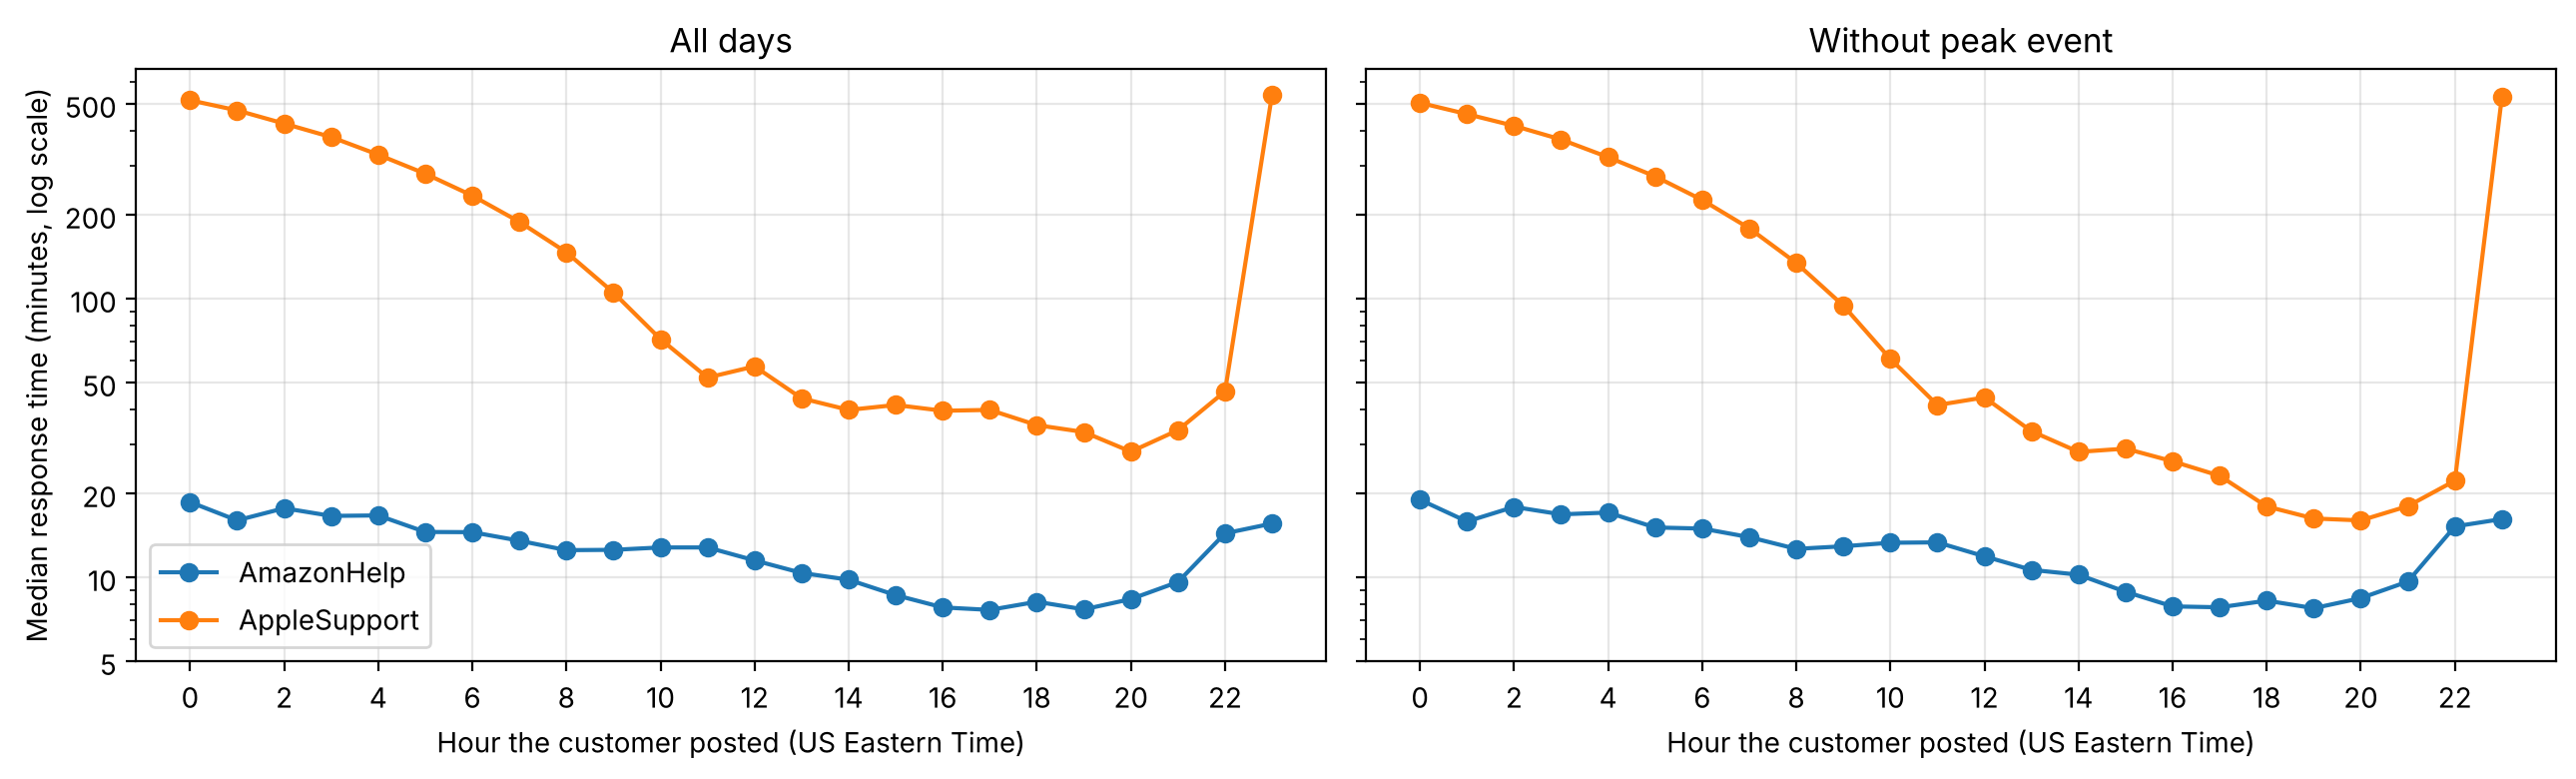

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (title, data) in zip(axes, versions.items()):
    hourly = data.groupby(["hour", "brand"])["response_minutes"].median().unstack()
    for brand in hourly.columns:
        ax.plot(hourly.index, hourly[brand], marker="o", label=brand)
    ax.set_yscale("log")
    ax.set_yticks([5, 10, 20, 50, 100, 200, 500], ["5", "10", "20", "50", "100", "200", "500"])
    ax.set_xticks(range(0, 24, 2))
    ax.set_title(title)
    ax.set_xlabel("Hour the customer posted (US Eastern Time)")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Median response time (minutes, log scale)")
axes[0].legend()
plt.tight_layout()
plt.show()

### 3. Response Time by Time of Day

In [4]:
# Median wait by brand and time of day, for both versions of the data
time_table = pd.concat(
    {title: data.groupby(["brand", "time_of_day"])["response_minutes"].median()
     for title, data in versions.items()},
    axis=1,
)
time_table.reindex(time_order, level="time_of_day").round(1)

All days  Without peak event
brand        time_of_day                                    
AmazonHelp   Morning (6-12)         13.1                13.5
             Afternoon (12-18)       9.3                 9.6
             Evening (18-24)        10.1                10.3
             Night (0-6)            16.5                16.8
AppleSupport Morning (6-12)        118.0                95.9
             Afternoon (12-18)      44.2                31.5
             Evening (18-24)        41.6                22.6
             Night (0-6)           436.9               416.4

### Findings: Posting Time

- **AmazonHelp replies fast at every hour** (median 9-17 min). Night posts (0-6) wait a little longer (16.5 min) than afternoon posts (9.3 min). Removing Black Friday to Cyber Monday changes almost nothing (9.6-16.8 min): Amazon was actually slightly *faster* on those busy days, so the hourly pattern is Amazon's normal behaviour.
- **AppleSupport depends strongly on posting time.** Over all days, night posts wait 437 min (over 7 hours) vs 44 min in the afternoon, about **10 times longer**. The curve jumps at **23:00 ET** and falls slowly until about 11:00, which suggests Apple mostly stops replying late at night.
- **The iOS bug made Apple slower during the day, but not at night.** Without the bug period (28% of Apple's cases), afternoon and evening waits drop to 32 and 23 min, while night waits stay at 416 min. So the night delay is not caused by the bug; without it, night posts wait about 13-18 times longer than afternoon or evening posts.

**Limitation:** we do not know each customer's real time zone, so we use US Eastern Time for everyone.

## Part 2: Wording

### 4. Polite and Rude Words

We remove @mentions and links, then flag polite and rude tweets with **regular expressions**. The word lists were built in rounds: we started from common words, then read random unflagged tweets and added the words we had missed.

- `\b` is a word boundary, so `hate` does not match "whatever".
- `\w*` allows extra letters, so `\w*fuck\w*` matches "fucking".
- `thank(?:s|you|u)?` matches "thanks" but not "Thanksgiving".

In [5]:
# Remove @mentions and links so they don't affect word matching
text = (cases["customer_text"]
        .str.replace(r"@\w+", "", regex=True)
        .str.replace(r"http\S+", "", regex=True))

thanks_words = [r"thank(?:s|you|u)?", "thx", "ty"]
other_polite_words = [
    "please", "pls", "plz", r"appreciate\w*", "grateful", "kindly", "sorry", "excuse me",
    "could you", "would you", "regards", "dear", "hi", "hello", r"good (?:morning|afternoon|evening)",
]
rude_words = [
    r"\w*fuck\w*", r"fuk\w*", r"\w*shit\w*", r"damn\w*", r"goddam\w*", "wtf", r"crap\w*", "hell",
    "ass", r"asshole\w*", "pissed", r"screw(?:ed|s)?", "stupid", r"idiot\w*", "dumb", "ridiculous",
    "worst", "terrible", "awful", "horrible", "useless", "pathetic", "rubbish", "garbage", "trash",
    "joke", "hate", r"sucks?", "annoying", "unacceptable", "disgusting", "incompetent", "clueless",
    "lame", r"scam\w*", r"cheat\w*", r"fraud\w*", r"liars?",
]

def flag(words):
    """True for tweets containing any of the words (as whole words, any case)."""
    pattern = r"\b(?:" + "|".join(words) + r")\b"
    return text.str.contains(pattern, case=False, regex=True)

cases["has_thanks"] = flag(thanks_words)
cases["is_polite_other"] = flag(other_polite_words)
cases["is_polite"] = cases["has_thanks"] | cases["is_polite_other"]
cases["is_rude"] = flag(rude_words)

cases[["is_polite", "is_rude"]].mean().round(3)

is_polite    0.179
is_rude      0.151
dtype: float64

### 5. Tone Groups

A tweet can contain both polite and rude words (*"please fix this shit"*), so we put each tweet into exactly one group:

| Group | Polite words | Rude words |
|---|---|---|
| Polite | yes | no |
| Neutral | no | no |
| Mixed | yes | yes |
| Rude | no | yes |

In [6]:
cases["tone"] = np.select(
    [cases["is_polite"] & cases["is_rude"], cases["is_polite"], cases["is_rude"]],
    ["Mixed", "Polite", "Rude"],
    default="Neutral",
)
tone_order = ["Polite", "Neutral", "Mixed", "Rude"]

cases["tone"].value_counts(normalize=True).reindex(tone_order).round(3)

tone
Polite     0.160
Neutral    0.689
Mixed      0.018
Rude       0.132
Name: proportion, dtype: float64

### 6. Response Time by Tone

In [7]:
cases.groupby(["brand", "tone"])["response_minutes"].median().unstack().reindex(columns=tone_order).round(1)

tone,Polite,Neutral,Mixed,Rude
brand,,,,
AmazonHelp,12.5,11.8,13.2,12.6
AppleSupport,75.4,66.6,95.4,94.3


### 7. Is It the Wording or the Time?

Rude tweets may cluster at night or during the peak event, when the brand is slow anyway. If so, the gap above is a **time effect**, not a wording effect (time is a *confounder*). We check this for Apple, where the gap appears.

In [8]:
apple = cases[cases["brand"] == "AppleSupport"]

print("Share of rude tweets (Apple):")
print("  during the iOS bug:", round(apple.loc[apple["in_event"], "is_rude"].mean(), 3))
print("  outside the iOS bug:", round(apple.loc[~apple["in_event"], "is_rude"].mean(), 3))
print(apple.groupby("time_of_day")["is_rude"].mean().reindex(time_order).round(3))

Share of rude tweets (Apple):
  during the iOS bug: 0.255
  outside the iOS bug: 0.174
time_of_day
Morning (6-12)       0.177
Afternoon (12-18)    0.187
Evening (18-24)      0.213
Night (0-6)          0.226
Name: is_rude, dtype: float64


In [9]:
# Median wait by tone within the same time of day (Apple, outside the iOS bug)
(apple[~apple["in_event"]]
 .groupby(["time_of_day", "tone"])["response_minutes"].median()
 .unstack().reindex(index=time_order, columns=tone_order).round(1))

tone,Polite,Neutral,Mixed,Rude
time_of_day,,,,
Morning (6-12),98.6,92.6,107.9,106.6
Afternoon (12-18),30.8,31.4,33.3,33.0
Evening (18-24),22.0,21.1,33.8,29.4
Night (0-6),401.2,415.2,419.2,432.8


### 8. Regression: Wording Effect After Controlling for Time

A regression controls for **the exact hour and the exact date** at the same time. For each brand:

$$\log(\text{response minutes}) = \text{wording} + \text{is first tweet} + \text{hour} + \text{date}$$

- **Log** of response time: waits are very skewed, and a coefficient $b$ then means the wait changes by about $(e^b - 1) \times 100\%$.
- **Hour** and **date** are categories (`C(...)`), one adjustment per hour and per day, so busy days such as the iOS bug or Black Friday are taken into account.
- **Polite words are split** into "thanks" words and other polite words, because "thanks" is often sarcastic (*"Thanks for ruining my presents"*) and may behave differently from words such as *please*.
- `is_first_tweet` controls for whether the tweet starts a conversation ("thanks" often appears at the end of one).
- Standard errors are robust to unequal variance (HC1).

In [10]:
wording = ["is_polite_other", "has_thanks", "is_rude"]
cases["log_minutes"] = np.log(cases["response_minutes"])
cases["date"] = cases["local_time"].dt.date.astype(str)

formula = "log_minutes ~ " + " + ".join(wording) + " + is_first_tweet + C(hour) + C(date)"
models = {brand: smf.ols(formula, data=group).fit(cov_type="HC1")
          for brand, group in cases.groupby("brand")}

rows = []
for brand, model in models.items():
    median_wait = cases.loc[cases["brand"] == brand, "response_minutes"].median()
    for w in wording:
        name = w + "[T.True]"
        low, high = model.conf_int().loc[name]
        effect = np.exp(model.params[name]) - 1
        rows.append({
            "brand": brand, "feature": w,
            "effect_%": effect * 100,
            "ci_low_%": (np.exp(low) - 1) * 100,
            "ci_high_%": (np.exp(high) - 1) * 100,
            "p_value": model.pvalues[name],
            "approx_minutes": effect * median_wait,   # effect at the brand's median wait
        })
effects = pd.DataFrame(rows)
effects.round(3)

,brand,feature,effect_%,ci_low_%,ci_high_%,p_value,approx_minutes
0,AmazonHelp,is_polite_other,11.566,9.965,13.190,0.000,1.390
1,AmazonHelp,has_thanks,-15.911,-17.675,-14.109,0.000,-1.912
2,AmazonHelp,is_rude,3.696,2.092,5.324,0.000,0.444
3,AppleSupport,is_polite_other,0.844,-0.343,2.045,0.164,0.607
4,AppleSupport,has_thanks,-3.079,-4.676,-1.454,0.000,-2.215
5,AppleSupport,is_rude,0.341,-0.653,1.345,0.502,0.245


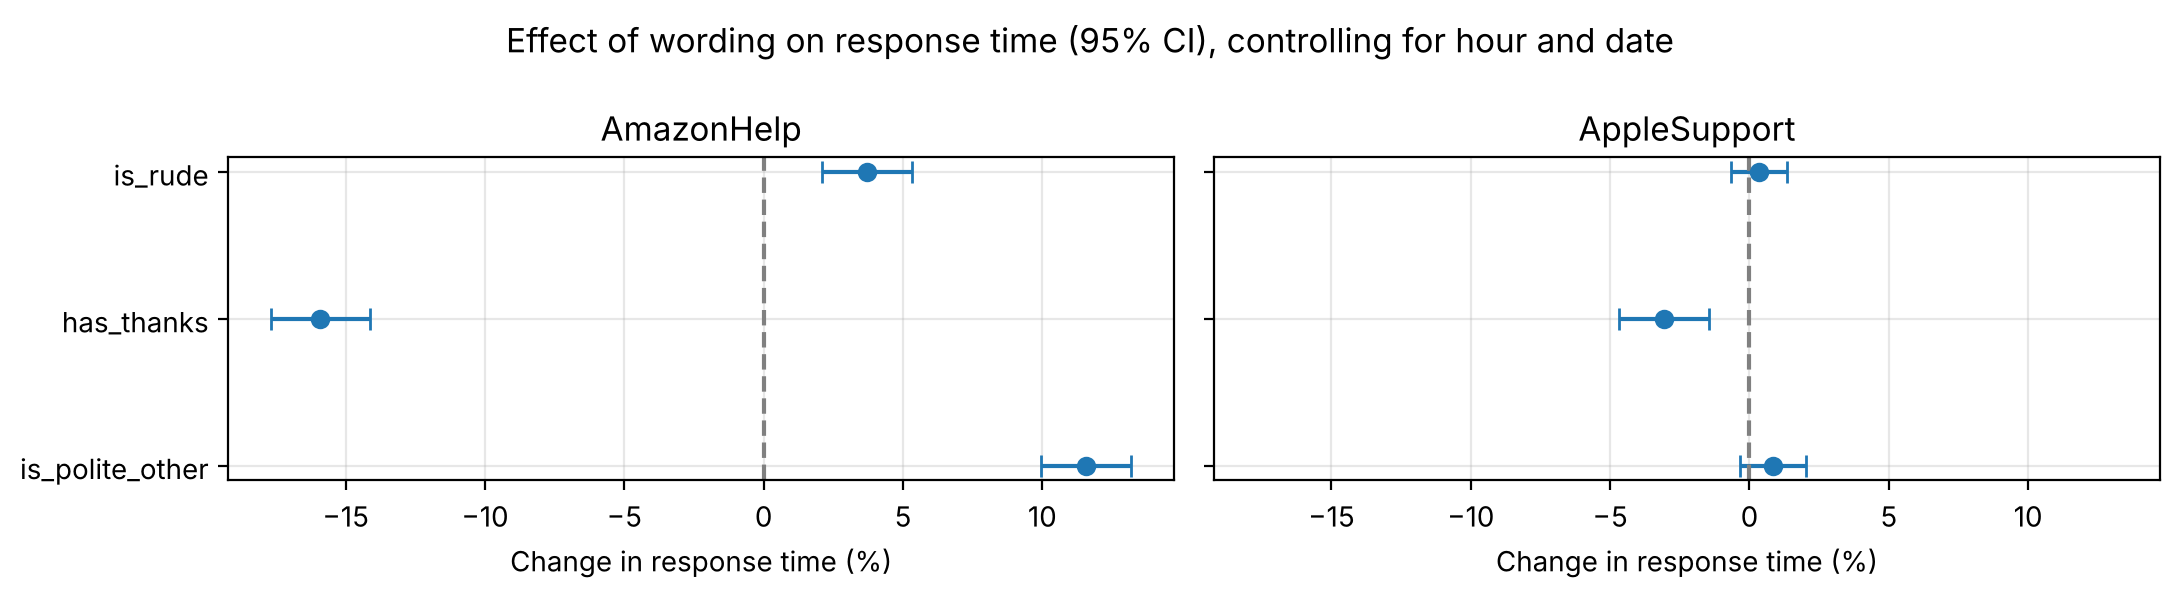

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3), sharex=True, sharey=True)
for ax, (brand, group) in zip(axes, effects.groupby("brand")):
    y = range(len(group))
    ax.errorbar(group["effect_%"], y, fmt="o", capsize=4,
                xerr=[group["effect_%"] - group["ci_low_%"], group["ci_high_%"] - group["effect_%"]])
    ax.axvline(0, color="gray", linestyle="--")
    ax.set_yticks(list(y), group["feature"])
    ax.set_title(brand)
    ax.set_xlabel("Change in response time (%)")
    ax.grid(alpha=0.3)
plt.suptitle("Effect of wording on response time (95% CI), controlling for hour and date")
plt.tight_layout()
plt.show()

### 9. Time vs Wording: Which Matters More?

Two measures for each brand:
- **Size:** from the regression above, how much slower is the slowest posting hour than the fastest, compared with the largest wording effect?
- **R²:** how much of the variation in (log) response time does posting hour alone explain, compared with the wording features alone?

In [12]:
rows = []
for brand, model in models.items():
    group = cases[cases["brand"] == brand]
    hour_coefs = pd.Series({0: 0.0})   # hour 0 is the baseline
    for name, value in model.params.items():
        if name.startswith("C(hour)"):
            hour_coefs[int(name.split("[T.")[1].rstrip("]"))] = value
    rows.append({
        "brand": brand,
        "fastest_hour": hour_coefs.idxmin(),
        "slowest_hour": hour_coefs.idxmax(),
        "slowest_vs_fastest_hour_%": (np.exp(hour_coefs.max() - hour_coefs.min()) - 1) * 100,
        "largest_wording_effect_%": effects.loc[effects["brand"] == brand, "effect_%"].abs().max(),
        "R2_hour_only": smf.ols("log_minutes ~ C(hour)", data=group).fit().rsquared,
        "R2_wording_only": smf.ols("log_minutes ~ " + " + ".join(wording), data=group).fit().rsquared,
    })
pd.DataFrame(rows).round(3)

,brand,fastest_hour,slowest_hour,slowest_vs_fastest_hour_%,largest_wording_effect_%,R2_hour_only,R2_wording_only
0,AmazonHelp,19,0,102.444,15.911,0.055,0.006
1,AppleSupport,20,0,1734.669,3.079,0.481,0.006


### Findings: Wording

- **How common:** 18% of tweets contain polite words and 15% rude words. In tone groups: 16% Polite, 69% Neutral, 2% Mixed, 13% Rude.
- **At first glance:** AmazonHelp waits are the same for every tone (11.8-13.2 min). AppleSupport looks slower for rude (94 min) and mixed (95 min) tweets than for neutral ones (67 min).
- **But rude tweets are posted at different times.** For Apple, 25.5% of tweets are rude during the iOS bug vs 17.4% outside it, and 22.6% at night vs 17.7% in the morning: exactly when Apple is slow anyway.
- **Within the same time of day** (outside the bug), the gap mostly disappears: in the afternoon, polite, neutral and rude tweets wait 31, 31 and 33 min.
- **The regression confirms this.** After controlling for the exact hour and date, rude wording changes Apple's wait by only +0.3% (95% CI -0.7% to +1.3%, not significant). For Amazon, rude tweets wait 3.7% longer (about half a minute).
- **Polite words have small, opposite effects for Amazon:** "thanks" tweets are answered about 16% faster (about 2 min), while other polite words (*please, could you, ...*) wait about 12% longer (about 1.4 min). For Apple both are small (-3% and +1%, the latter not significant). One possible reason, not tested here, is that "please" tweets often ask for something new while many "thanks" tweets close a conversation.
- **Time vs wording:** controlling for date and wording, the slowest hour (midnight) is about **2x** slower than the fastest for Amazon and about **18x** for Apple, while no wording effect is larger than 16% (Amazon) or 3% (Apple). Posting hour alone explains 5.5% (Amazon) and 48% (Apple) of the variation in log response time; wording explains 0.6% for each brand.

## RQ1 Summary

**Answer to RQ1: for both brands, *when* a customer posts matters more than *how* they write. The gap is huge for AppleSupport and moderate for AmazonHelp.**

| | Posting time | Wording (after controlling for hour and date) | R²: hour vs wording |
|---|---|---|---|
| **AmazonHelp** | Night 16.5 min vs afternoon 9.3 min; slowest hour about 2x the fastest; same without Black Friday | Small: rude +4%, "please"-type +12%, "thanks" -16% (each 2 min or less) | 5.5% vs 0.6% |
| **AppleSupport** | Night 437 min vs afternoon 44 min; slowest hour about 18x the fastest; night delay remains without the iOS bug | Tiny: rude +0.3% (not significant), "thanks" -3% | 48% vs 0.6% |

**Key points**
1. **Apple mostly stops replying late at night.** Tweets posted after about 23:00 ET wait until the next morning. This is not caused by the iOS bug. Amazon replies around the clock.
2. **Rude tweets only look slower.** They are more common at night and during the iOS bug, when Apple is slow anyway. Compared at the same hour on the same day, rude wording makes almost no difference.
3. **Polite wording has small, mixed effects for Amazon** (about 2 min either way) and almost none for Apple.
4. **For the waiting-time estimate in the Prediction step,** posting hour and date are useful inputs; wording changes the estimate by only a few minutes.

**Limitations**
- We do not know each customer's real time zone; we use US Eastern Time for everyone.
- Wording is measured only with hand-made word lists, which were not checked by hand. They cannot read sarcasm or context (e.g. sarcastic "thanks"), so some tweets are labelled wrongly, especially as polite.
- The data covers only about 9 weeks (Oct-Dec 2017), with unusual events.
- The regression shows association, not causation: tweets with different wording may also differ in ways we cannot see (e.g. harder problems).